In [1]:
import configparser

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('../data.ini')
data = data['DEFAULT']

In [3]:
mutclust = pd.read_csv('../' + data['mutclustsw___all_noHypoHyper___out'], sep='\t', engine='python', comment='#')

In [4]:
oncodriveclustl_coadread = pd.read_csv('../' + data['oncodriveclustl___all_noHypoHyper'] + 'output_coadreadParams/clusters_results.tsv', sep='\t', engine='python', comment='#')

In [5]:
oncodriveclustl_default = pd.read_csv('../' + data['oncodriveclustl___all_noHypoHyper'] + 'output_defaultParams/clusters_results.tsv', sep='\t', engine='python', comment='#')

In [6]:
mutclust_threshold = float(data['mutclustSignificanceThreshold'])
oncodriveclustl_coadreadParams_threshold = float(data['oncodriveclustlSignificanceThreshold'])
oncodriveclustl_defaultParams_threshold = float(data['oncodriveclustlSignificanceThreshold'])

## thresholds

In [7]:
pv_qfreq = 0.01

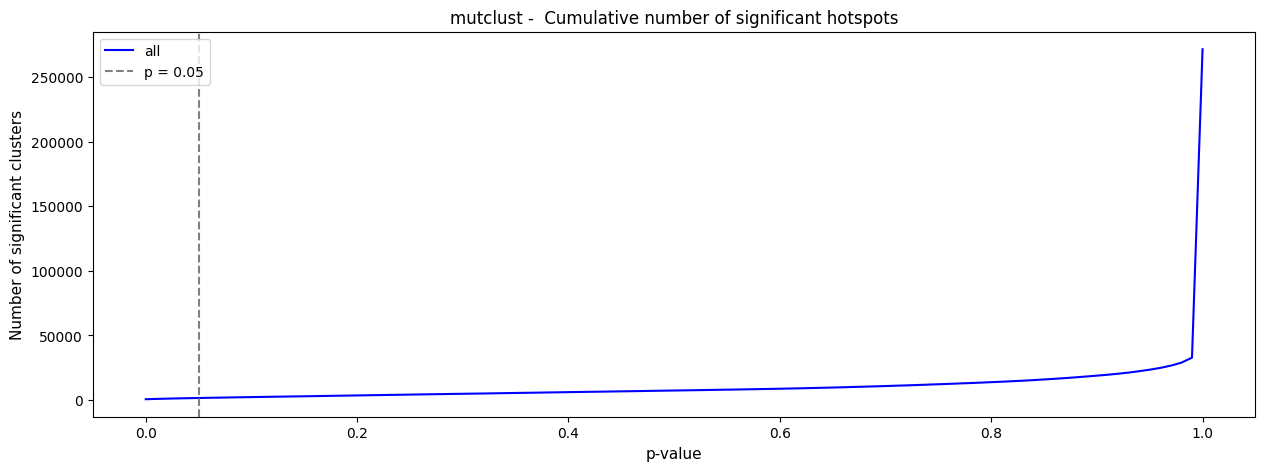

In [8]:
# create dataframes containing p values and the number of genes with p-value lower than that
numGenes_pvLower = pd.DataFrame(
    [(i, len(mutclust.loc[mutclust['Pvalue'] <= i, 'Gene'])) for i in np.clip(np.arange(0, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)

# plot
plt.figure(figsize=(15, 5))
plt.title('mutclust -  Cumulative number of significant hotspots')
plt.plot(numGenes_pvLower.set_index('p'), label='all', color='blue')
plt.xlabel('p-value', fontsize=11)
plt.ylabel('Number of significant clusters', fontsize=11)
# add vertical line for the threshold
plt.axvline(x=mutclust_threshold, color='grey', linestyle='--', label=f'p = {mutclust_threshold}')
plt.legend(loc='upper left', fontsize=10)
plt.savefig('../' + data['plots'] + f'hotspots/mutclust_cumulativeNumSignificantClusters.png')
plt.show()

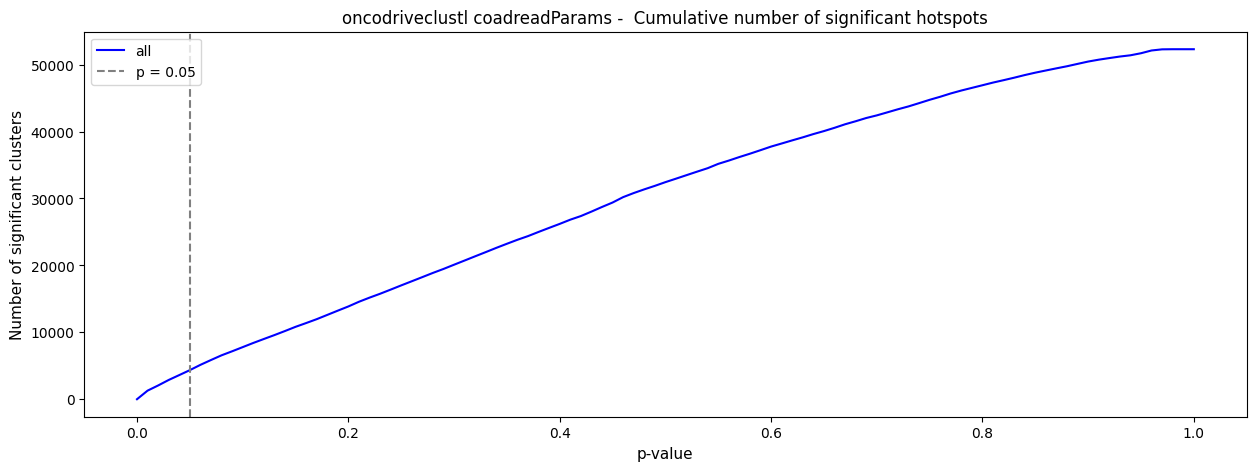

In [9]:
# create dataframes containing p values and the number of genes with p-value lower than that
numGenes_pvLower = pd.DataFrame(
    [(i, len(oncodriveclustl_coadread.loc[oncodriveclustl_coadread['P'] <= i, 'SYMBOL'])) for i in np.clip(np.arange(0, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)

# plot
plt.figure(figsize=(15, 5))
plt.title('oncodriveclustl coadreadParams -  Cumulative number of significant hotspots')
plt.plot(numGenes_pvLower.set_index('p'), label='all', color='blue')
plt.xlabel('p-value', fontsize=11)
plt.ylabel('Number of significant clusters', fontsize=11)
# add vertical line for the threshold
plt.axvline(x=oncodriveclustl_coadreadParams_threshold, color='grey', linestyle='--', label=f'p = {oncodriveclustl_coadreadParams_threshold}')
plt.legend(loc='upper left', fontsize=10)
plt.savefig('../' + data['plots'] + f'hotspots/oncodriveclustl_coadreadParams_cumulativeNumSignificantClusters.png')
plt.show()

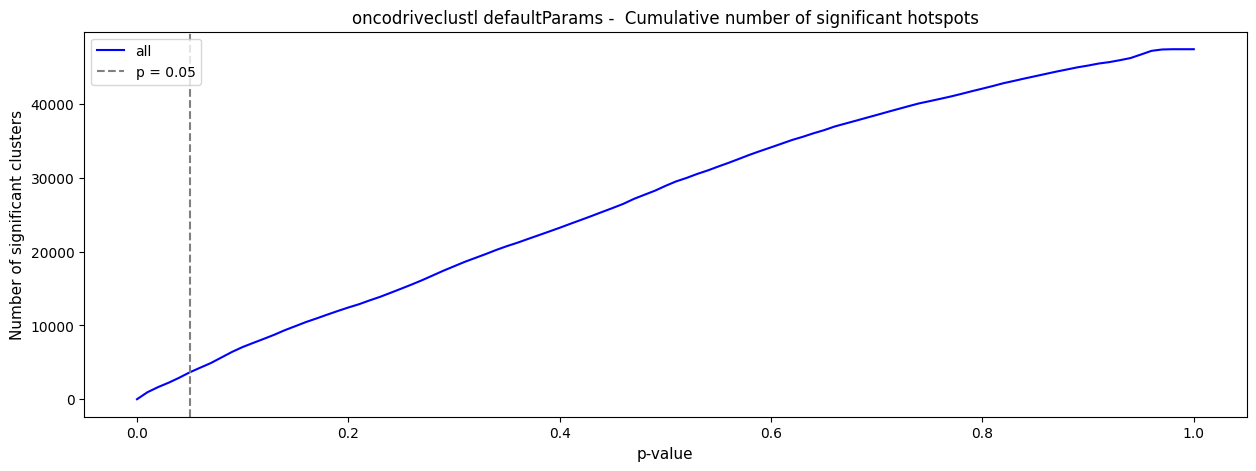

In [10]:
# create dataframes containing p values and the number of genes with p-value lower than that
numGenes_pvLower = pd.DataFrame(
    [(i, len(oncodriveclustl_default.loc[oncodriveclustl_default['P'] <= i, 'SYMBOL'])) for i in np.clip(np.arange(0, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)

# plot
plt.figure(figsize=(15, 5))
plt.title('oncodriveclustl defaultParams -  Cumulative number of significant hotspots')
plt.plot(numGenes_pvLower.set_index('p'), label='all', color='blue')
plt.xlabel('p-value', fontsize=11)
plt.ylabel('Number of significant clusters', fontsize=11)
# add vertical line for the threshold
plt.axvline(x=oncodriveclustl_defaultParams_threshold, color='grey', linestyle='--', label=f'p = {oncodriveclustl_defaultParams_threshold}')
plt.legend(loc='upper left', fontsize=10)
plt.savefig('../' + data['plots'] + f'hotspots/oncodriveclustl_defaultParams_cumulativeNumSignificantClusters.png')
plt.show()

## clusters lengths

In [11]:
oncodriveclustl_coadread

,RANK,SYMBOL,ENSID,CGC,CHROMOSOME,STRAND,COORDINATES,MAX_COORD,WIDTH,N_MUT,N_SAMPLES,FRA_UNIQ_SAMPLES,SCORE,P
0,1,KRAS,ENSG00000133703,True,12,-,"25398274,25398285",25398283,12,347,341,0.982709,17775.6341,5.715865e-07
1,1,KRAS,ENSG00000133703,True,12,-,"25380268,25380289",25380277,22,34,25,0.735294,178.5087,5.465183e-01
2,1,KRAS,ENSG00000133703,True,12,-,"25378561,25378562",25378562,2,25,25,1.000000,142.2248,5.517939e-01
3,1,KRAS,ENSG00000133703,True,12,-,"25378647,25378648",25378647,2,6,6,1.000000,8.0761,5.713155e-01
4,1,KRAS,ENSG00000133703,True,12,-,"25398214,25398220",25398218,7,4,4,1.000000,2.1226,5.721818e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52300,13740,ZNF526,ENSG00000167625,False,19,+,"42729118,42729138",42729121,21,3,3,1.000000,4.7867,7.164937e-01
52301,13740,ZNF526,ENSG00000167625,False,19,+,"42728572,42728580",42728576,9,2,2,1.000000,2.6316,9.594353e-01
52302,16207,MUC3A,ENSG00000169894,False,7,+,"100551701,100551715",100551704,15,3,3,1.000000,21.8761,4.689943e-01
52303,18134,ZNF788,ENSG00000214189,False,19,+,"12244345,12244353",12244345,9,3,3,1.000000,25.7812,3.169016e-02


In [12]:
oncodriveclustl_coadread['COORDINATES'].str.split(',', expand=True)

,0,1
0,25398274,25398285
1,25380268,25380289
2,25378561,25378562
3,25378647,25378648
4,25398214,25398220
...,...,...
52300,42729118,42729138
52301,42728572,42728580
52302,100551701,100551715
52303,12244345,12244353


In [13]:
mutclust['len'] = mutclust['End'] - mutclust['Start'] + 1
oncodriveclustl_coadread[['Start', 'End']] = oncodriveclustl_coadread['COORDINATES'].str.split(',', expand=True).astype(int)
oncodriveclustl_coadread['len'] = oncodriveclustl_coadread['End'] - oncodriveclustl_coadread['Start'] + 1
oncodriveclustl_default[['Start', 'End']] = oncodriveclustl_default['COORDINATES'].str.split(',', expand=True).astype(int)
oncodriveclustl_default['len'] = oncodriveclustl_default['End'] - oncodriveclustl_default['Start'] + 1

In [14]:
mutclust

,Gene,Start,End,Scoresum,Recursion,Mutation,NES,Pvalue,len
0,ENST00000263100,288,292,0.167507,Y,4,1.426647,0.099010,5
1,ENST00000263100,244,245,0.132323,N,3,0.274188,0.336634,2
2,ENST00000263100,182,185,0.078618,Y,2,-1.484975,0.950495,4
3,ENST00000263100,443,443,0.043434,Y,1,-2.637434,0.990099,1
4,ENST00000263100,4,4,0.043434,N,1,-2.637434,0.990099,1
...,...,...,...,...,...,...,...,...,...
271413,ENST00000294854,613,613,0.089980,N,1,-2.247365,0.990099,1
271414,ENST00000294854,759,759,0.089980,N,1,-2.247365,0.990099,1
271415,ENST00000294854,853,853,0.089980,N,1,-2.247365,0.990099,1
271416,ENST00000294854,986,986,0.089980,N,1,-2.247365,0.990099,1


/tmp/ipykernel_212047/4116550598.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['label'] = df['len'].apply(assign_label)
/tmp/ipykernel_212047/4116550598.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['label'] = df['len'].apply(assign_label)
/tmp/ipykernel_212047/4116550598.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org

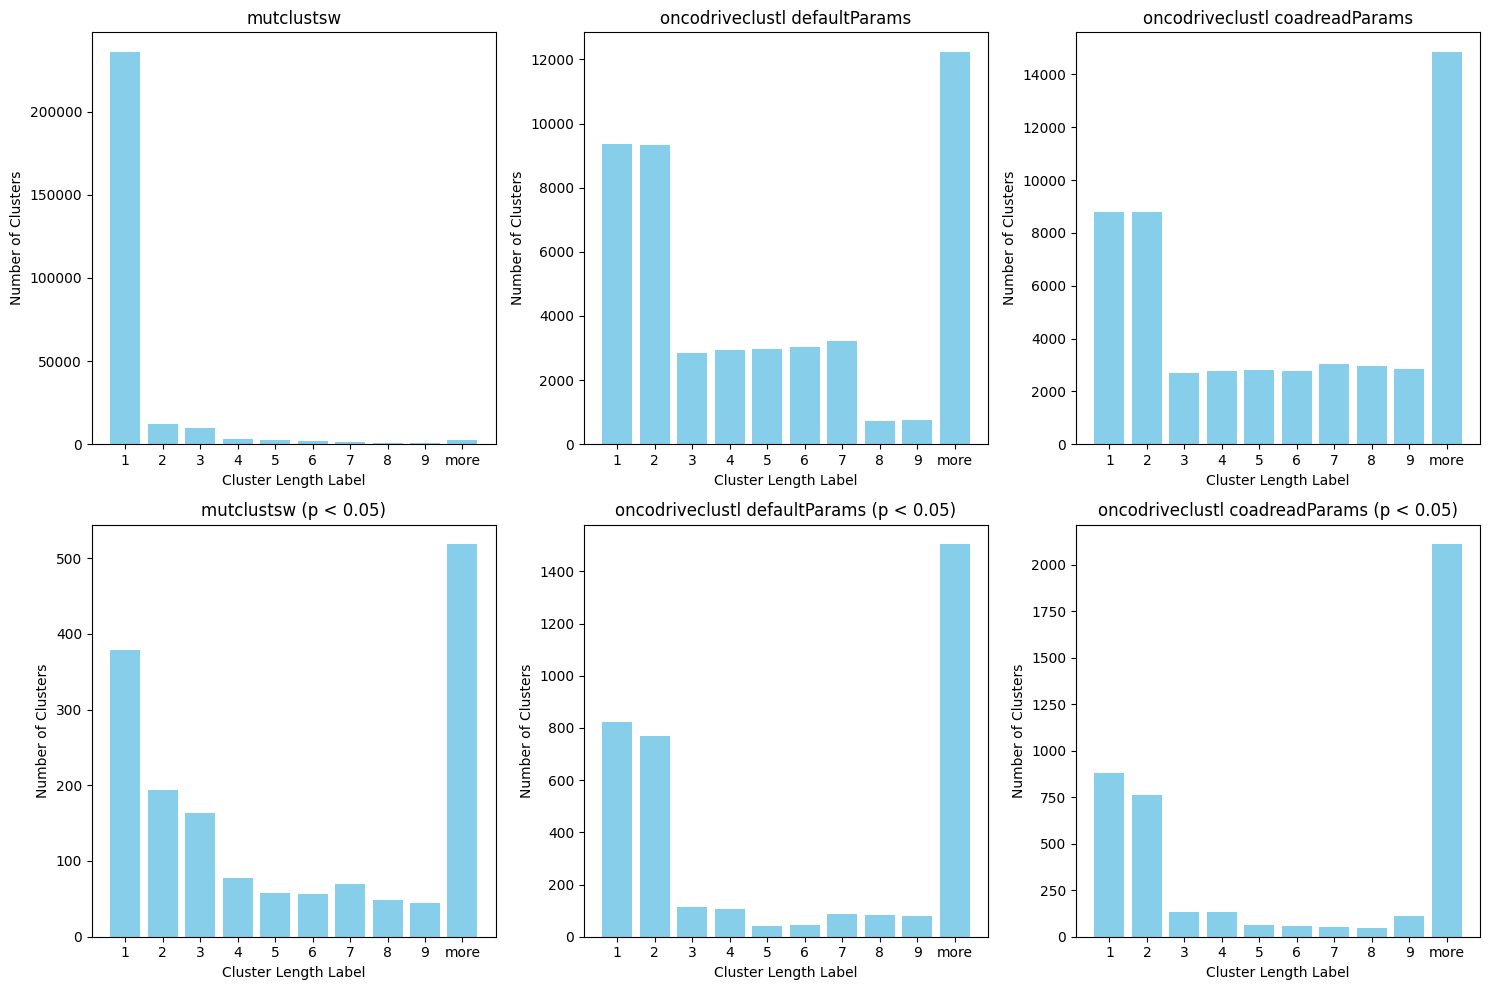

In [15]:
# Function to assign labels based on the 'len' value
def assign_label(value):
    if value <= 9:
        return str(value)
    else:
        return 'more'

# Function to plot the bar graph for a given dataframe
def plot_bar(ax, df, title):
    df['label'] = df['len'].apply(assign_label)
    # Define the desired order of labels
    order = ['1', '2', '3', '4', '5', '6', '7', '8', '9', 'more']
    label_counts = df['label'].value_counts().reindex(order, fill_value=0)
    
    ax.bar(label_counts.index, label_counts.values, color='skyblue')
    ax.set_xlabel("Cluster Length Label")
    ax.set_ylabel("Number of Clusters")
    ax.set_title(title)

# Create a figure with three subplots arranged in one row
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

# Plot each dataframe on its respective axis
plot_bar(axs[0, 0], mutclust, "mutclustsw")
plot_bar(axs[0, 1], oncodriveclustl_default, "oncodriveclustl defaultParams")
plot_bar(axs[0, 2], oncodriveclustl_coadread, "oncodriveclustl coadreadParams")
plot_bar(axs[1, 0], mutclust[mutclust['Pvalue'] < mutclust_threshold], f"mutclustsw (p < {mutclust_threshold})")
plot_bar(axs[1, 1], oncodriveclustl_default[oncodriveclustl_default['P'] < oncodriveclustl_defaultParams_threshold], f"oncodriveclustl defaultParams (p < {oncodriveclustl_defaultParams_threshold})")
plot_bar(axs[1, 2], oncodriveclustl_coadread[oncodriveclustl_coadread['P'] < oncodriveclustl_coadreadParams_threshold], f"oncodriveclustl coadreadParams (p < {oncodriveclustl_coadreadParams_threshold})")

plt.tight_layout()
plt.savefig('../' + data['plots'] + 'hotspots/clusterLengthsDistribution.png')
plt.show()